# CO2 prediction from environmental data
edit

## Setup
imports, constants and sensor names used throughout the notebook

In [43]:
# Required packages for the project
%pip install pandas numpy scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Loading and parsing

In [44]:
import pandas as pd
import json

# Load your raw env sensor data
df_raw = pd.read_csv("data/raw/5EnvSensor_MayToDec2024_180kRows.csv")

print(df_raw.shape)
df_raw.head()

(179447, 8)


,id,sensorid,devicetype,jsondata,status,processing_errors,createdate,processdate
0,2,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 03:11:58.210358+11,2024-02-29 03:11:58.210358+11
1,4,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:08.833822+11,2024-02-29 17:09:08.833822+11
2,5,6012002000326,env,"[{""values"": [{""time"": 1702270857, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:12.444245+11,2024-02-29 17:09:12.444245+11
3,16,6012002000777,env,"[{""values"": [{""time"": 1683326565, ""value"": 4.1...",Processed,NaN,2024-02-29 17:10:24.443407+11,2024-02-29 17:10:24.443407+11
4,24,6012002000869,env,"[{""values"": [{""time"": 1709186696, ""value"": 4.1...",Processed,NaN,2024-02-29 17:11:11.348578+11,2024-02-29 17:11:11.348578+11


In [45]:
# 1. Re-run the updated function definition (the one with device_time added)
def parse_jsondata(row):
    readings = json.loads(row['jsondata'])
    parsed = {
        'sensorid': row['sensorid'],
        'timestamp': row['createdate'],
        'device_time': None
    }
    for item in readings:
        var_name = item['variable']['name']
        values_list = item.get('values', [])
        if not values_list:
            continue
        value_entry = values_list[0]
        parsed[var_name] = value_entry.get('value')
        parsed['device_time'] = value_entry.get('time')
    return parsed

#Rebuild df_env from df_raw using the updated function
parsed_rows = df_raw.apply(parse_jsondata, axis=1)
df_env = pd.DataFrame(list(parsed_rows))


Data auditing

In [46]:
#checking each variable to see how many had missing values
df_env.isna().sum()


sensorid                                 0
timestamp                                0
device_time                              0
Battery                                  0
Carbon dioxide                           0
Humidity                                 0
Formaldehyde                        113380
Pressure                                 0
Temperature                              0
Light Volatile Organic Compounds     29566
Particulate matter 1                  1709
Particulate matter 4                  1709
Particulate matter 2.5                1709
Particulate matter 10                 1709
dtype: int64

In [47]:
#checking if the duplicated data exist for a particular sensor over time
duplicates = df_env.duplicated(subset=['sensorid', 'device_time'], keep=False)
print(f"Duplicate rows: {duplicates.sum()}")
#checking duplicated columns if every entry is fully identical over time
compare_cols = [c for c in df_env.columns if c != 'timestamp']

key_dupes = df_env[df_env.duplicated(subset=['sensorid', 'device_time'], keep=False)]
fully_identical = key_dupes.duplicated(subset=compare_cols, keep=False).sum()

print(f"Of {len(key_dupes)} rows sharing sensorid+device_time, {fully_identical} are identical in every other column")

Duplicate rows: 136996
Of 136996 rows sharing sensorid+device_time, 136996 are identical in every other column


In [48]:
# How many rows share each (sensorid, device_time) pair?
group_sizes = df_env.groupby(['sensorid', 'device_time']).size()
print(group_sizes.value_counts().sort_index())

# Convert once, properly, handling the mixed +11/+10 offsets
df_env['timestamp'] = pd.to_datetime(df_env['timestamp'], utc=True)

# Now this is simpler and won't error
dupe_groups = df_env[df_env.duplicated(subset=['sensorid', 'device_time'], keep=False)]
time_spread = dupe_groups.groupby(['sensorid', 'device_time'])['timestamp'].agg(lambda x: x.max() - x.min())
print(time_spread.describe())

1        42451
2          299
3           37
4           26
5            9
6            2
7            4
8            2
9            1
10           1
11           1
16           1
19           1
22           1
25           1
10926        1
15431        1
21363        1
29342        2
29566        1
Name: count, dtype: int64
count                         392
mean       2 days 15:56:08.012893
std       22 days 10:25:49.077020
min        0 days 00:00:02.597510
25%        0 days 00:08:23.510879
50%        0 days 00:10:37.513971
75%        0 days 00:10:47.792948
max      227 days 03:06:27.015886
Name: timestamp, dtype: object


In [49]:
# Check Battery specifically within one of the big duplicate groups
one_group = df_env[(df_env['sensorid'] == 6012002000241)]
one_group['Battery'].value_counts().head(10)

# Check Battery value diversity within each sensor's duplicate group
for sid, dtime in dupe_groups.groupby(['sensorid', 'device_time']).size().sort_values(ascending=False).head(6).index:
    group = df_env[(df_env['sensorid'] == sid) & (df_env['device_time'] == dtime)]
    print(f"Sensor {sid}, device_time {dtime}: {len(group)} rows, {group['Battery'].nunique()} unique Battery values")

# Keep a copy with duplicates intact, for demonstrating the data quality issue
df_env_with_dupes = df_env.copy()

# Now clean as normal — this is what you'll use for modelling going forward
df_env = df_env.drop_duplicates(subset=['sensorid', 'device_time'], keep='first').reset_index(drop=True)
print(df_env.shape)


Sensor 6012002000241, device_time 1747660084: 29566 rows, 1 unique Battery values
Sensor 6012002000241, device_time 1702273965: 29342 rows, 1 unique Battery values
Sensor 6012002000326, device_time 1702270857: 29342 rows, 1 unique Battery values
Sensor 6012002000227, device_time 1702271273: 21363 rows, 1 unique Battery values
Sensor 6012002000869, device_time 1718300744: 15431 rows, 1 unique Battery values
Sensor 6012002000777, device_time 1683326565: 10926 rows, 1 unique Battery values
(42843, 14)


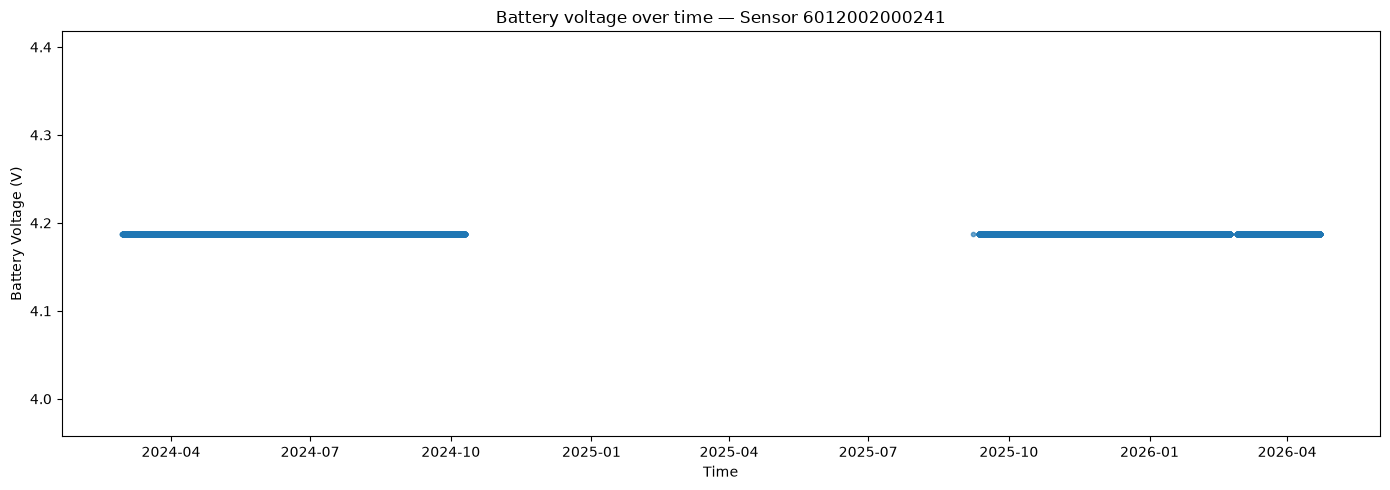

In [50]:
import matplotlib.pyplot as plt

# Pick one of the heavily-duplicated sensors to show clearly
sensor_id = 6012002000241

sensor_data = df_env_with_dupes[df_env_with_dupes['sensorid'] == sensor_id].sort_values('timestamp')

plt.figure(figsize=(14, 5))
plt.plot(sensor_data['timestamp'], sensor_data['Battery'], marker='.', linestyle='none', alpha=0.4)
plt.xlabel('Time')
plt.ylabel('Battery Voltage (V)')
plt.title(f'Battery voltage over time — Sensor {sensor_id}')
plt.tight_layout()
plt.show()


2024-02-28 16:11:58.210358+00:00 2024-10-10 04:55:45.402148+00:00
224 days 12:43:47.191790


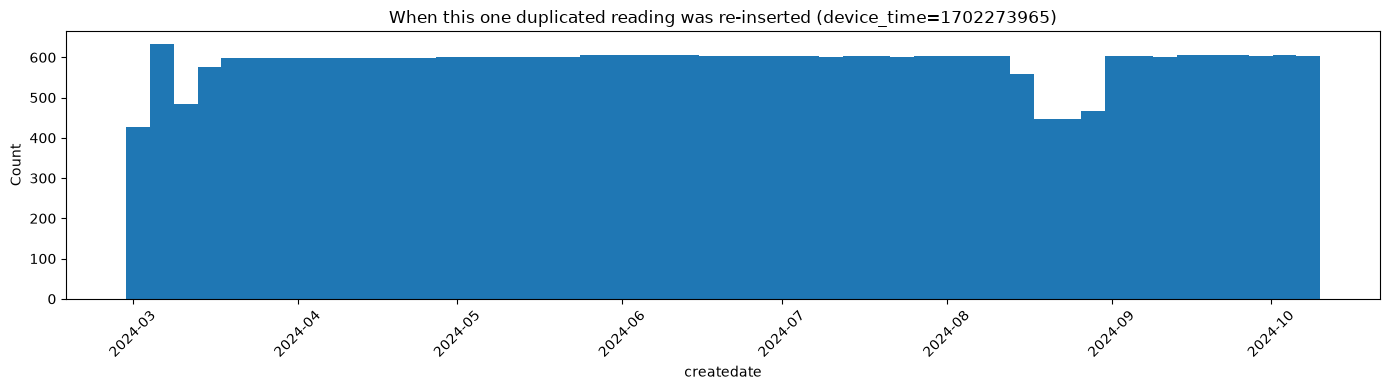

29342
int64
device_time
1747660084    29566
1702273965    29342
Name: count, dtype: int64


In [51]:
# Look at just one of the two mega-duplicate-groups for this sensor
group_data = df_env_with_dupes[
    (df_env_with_dupes['sensorid'] == sensor_id) & 
    (df_env_with_dupes['device_time'] == 1702273965)  # one of the two device_times you found
]

print(group_data['timestamp'].min(), group_data['timestamp'].max())
print(group_data['timestamp'].max() - group_data['timestamp'].min())

plt.figure(figsize=(14, 4))
plt.hist(group_data['timestamp'], bins=50)
plt.xlabel('createdate')
plt.ylabel('Count')
plt.title(f'When this one duplicated reading was re-inserted (device_time={1702273965})')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(len(group_data))
print(df_env_with_dupes['device_time'].dtype)
print(df_env_with_dupes[df_env_with_dupes['sensorid'] == sensor_id]['device_time'].value_counts().head())

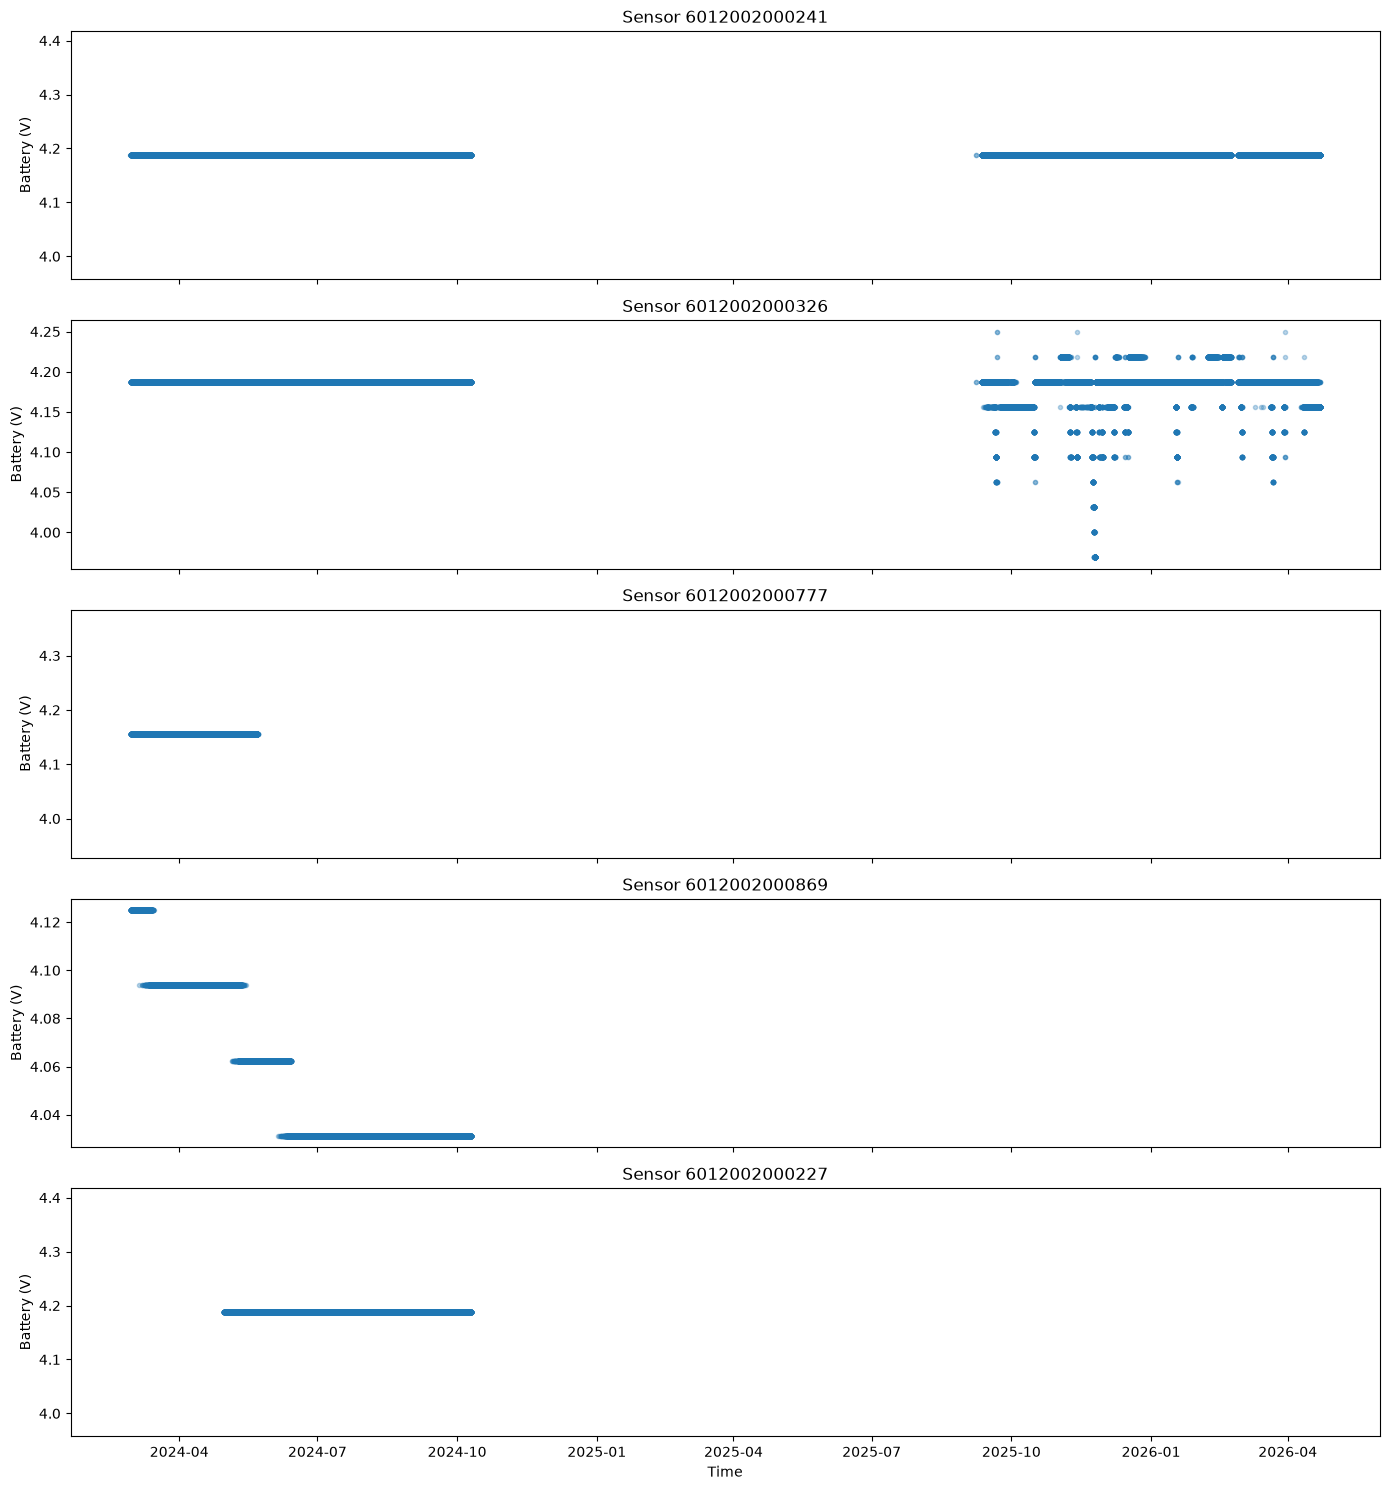

In [52]:
sensors = df_env_with_dupes['sensorid'].unique()
fig, axes = plt.subplots(len(sensors), 1, figsize=(14, 3 * len(sensors)), sharex=True)

for ax, sid in zip(axes, sensors):
    sensor_data = df_env_with_dupes[df_env_with_dupes['sensorid'] == sid].sort_values('timestamp')
    ax.plot(sensor_data['timestamp'], sensor_data['Battery'], marker='.', linestyle='none', alpha=0.3)
    ax.set_title(f'Sensor {sid}')
    ax.set_ylabel('Battery (V)')

plt.xlabel('Time')
plt.tight_layout()
plt.show()

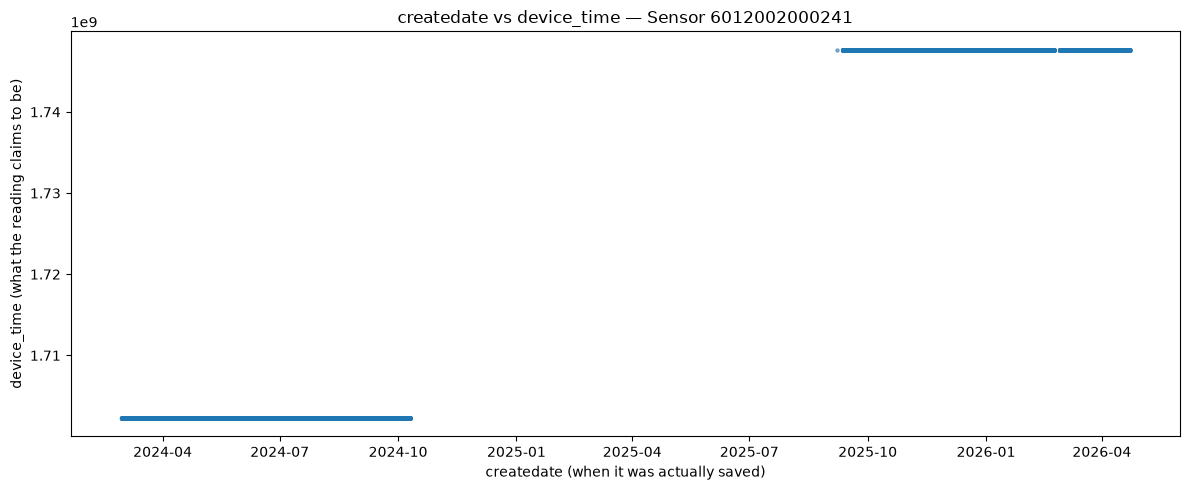

In [53]:
one_sensor = df_env_with_dupes[df_env_with_dupes['sensorid'] == sensor_id]

plt.figure(figsize=(12, 5))
plt.scatter(one_sensor['timestamp'], one_sensor['device_time'], alpha=0.3, s=5)
plt.xlabel('createdate (when it was actually saved)')
plt.ylabel('device_time (what the reading claims to be)')
plt.title(f'createdate vs device_time — Sensor {sensor_id}')
plt.tight_layout()
plt.show()

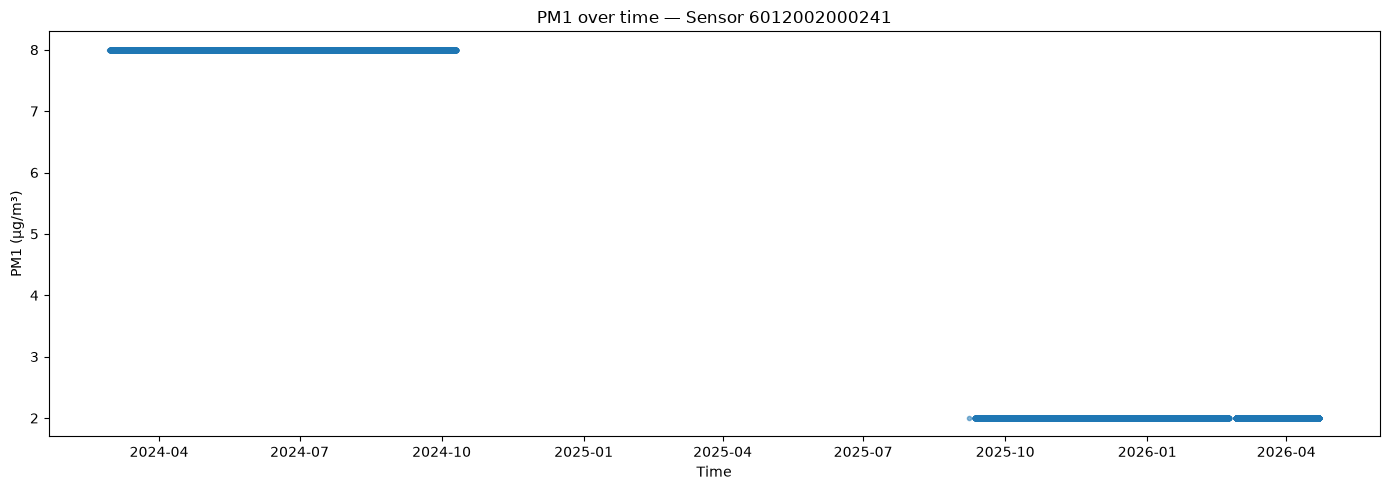

In [54]:
plt.figure(figsize=(14, 5))
plt.plot(one_sensor['timestamp'], one_sensor['Particulate matter 1'], marker='.', linestyle='none', alpha=0.3)
plt.xlabel('Time')
plt.ylabel('PM1 (µg/m³)')
plt.title(f'PM1 over time — Sensor {sensor_id}')
plt.tight_layout()
plt.show()

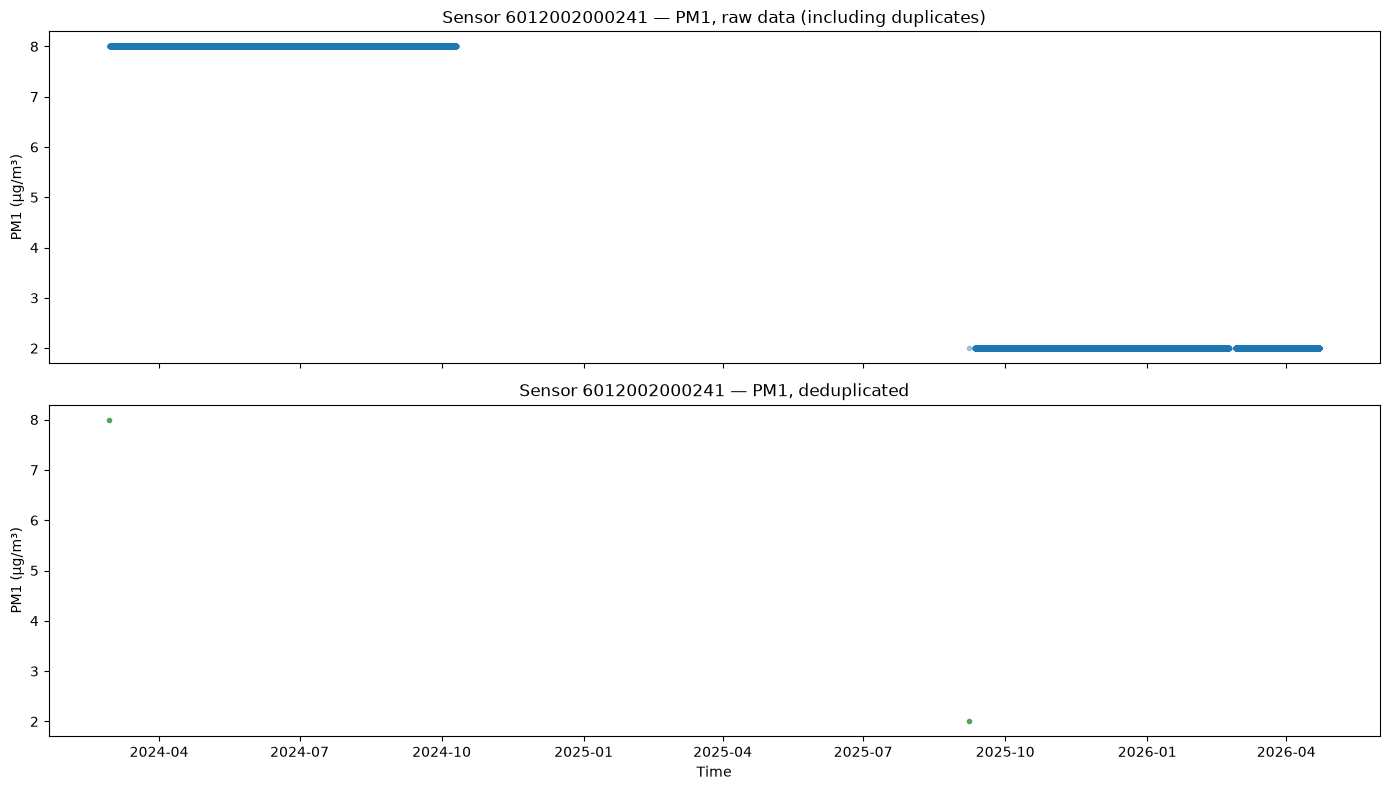

In [55]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Top: full data including duplicates — flat bands
axes[0].plot(one_sensor['timestamp'], one_sensor['Particulate matter 1'], marker='.', linestyle='none', alpha=0.2)
axes[0].set_title(f'Sensor {sensor_id} — PM1, raw data (including duplicates)')
axes[0].set_ylabel('PM1 (µg/m³)')

# Bottom: deduplicated data — should show genuine fluctuation
clean_sensor = df_env[df_env['sensorid'] == sensor_id].sort_values('timestamp')
axes[1].plot(clean_sensor['timestamp'], clean_sensor['Particulate matter 1'], marker='.', linestyle='none', alpha=0.6, color='green')
axes[1].set_title(f'Sensor {sensor_id} — PM1, deduplicated')
axes[1].set_ylabel('PM1 (µg/m³)')

plt.xlabel('Time')
plt.tight_layout()
plt.show()

In [56]:

dupe_group_std = one_group['Particulate matter 1'].std()
clean_std = clean_sensor['Particulate matter 1'].std()
print(f"Std within one duplicate group: {dupe_group_std}")
print(f"Std across genuinely distinct readings: {clean_std}")

Std within one duplicate group: 3.000003774535628
Std across genuinely distinct readings: 4.242640687119285


In [57]:
# Build a reliability summary table across every sensor
summary_rows = []

for sid in df_env_with_dupes['sensorid'].unique():
    sensor_data = df_env_with_dupes[df_env_with_dupes['sensorid'] == sid]
    total_rows = len(sensor_data)
    distinct_readings = sensor_data.drop_duplicates(subset=['sensorid', 'device_time']).shape[0]
    pct_real = round(distinct_readings / total_rows * 100, 1)
    
    summary_rows.append({
        'sensorid': sid,
        'total_rows': total_rows,
        'distinct_readings': distinct_readings,
        'pct_real_data': pct_real,
        'unique_co2_values': sensor_data['Carbon dioxide'].nunique(),
        'unique_pm1_values': sensor_data['Particulate matter 1'].nunique(),
    })

reliability_summary = pd.DataFrame(summary_rows).sort_values('pct_real_data')
print(reliability_summary)

        sensorid  total_rows  distinct_readings  pct_real_data  \
0  6012002000241       58908                  2            0.0   
2  6012002000777       10926                  1            0.0   
4  6012002000227       21363                  1            0.0   
3  6012002000869       29341              13800           47.0   
1  6012002000326       58909              29039           49.3   

   unique_co2_values  unique_pm1_values  
0                  2                  2  
2                  1                  1  
4                  1                  1  
3                222                 68  
1                245                 21  


In [58]:
# Filter down to your 2 reliable sensors
df_model = df_env[df_env['sensorid'].isin([6012002000869, 6012002000326])].copy()

#defining the sensor names of the 2 reliable sensors
sensor_names = {
    6012002000869: 'Upper Compactus',
    6012002000326: 'Unknown Room',
}

print(df_model.shape)
print(df_model['sensorid'].value_counts())

(42839, 14)
sensorid
6012002000326    29039
6012002000869    13800
Name: count, dtype: int64


In [59]:
# Rename columns to clean, consistent names
df_model = df_model.rename(columns={
    'Carbon dioxide': 'co2',
    'Temperature': 'temperature',
    'Humidity': 'humidity',
    'Pressure': 'pressure',
    'Formaldehyde': 'formaldehyde',
    'Light Volatile Organic Compounds': 'voc',
    'Particulate matter 1': 'pm1',
    'Particulate matter 4': 'pm4',
    'Particulate matter 2.5': 'pm2_5',
    'Particulate matter 10': 'pm10',
})

df_model.head()

,sensorid,timestamp,device_time,Battery,co2,humidity,formaldehyde,pressure,temperature,voc,pm1,pm4,pm2_5,pm10
1,6012002000326,2024-02-29 06:09:12.444245+00:00,1702270857,4.1875,525,68,5.0,1012,23.8,7.0,6.0,6.0,6.0,6.0
3,6012002000869,2024-02-29 06:11:11.348578+00:00,1709186696,4.1250,465,56,17.0,1010,24.3,0.0,2.0,2.0,2.0,2.0
4,6012002000869,2024-02-29 06:24:31.400806+00:00,1709187297,4.1250,445,56,17.0,1010,24.0,0.0,2.0,5.0,4.0,5.0
5,6012002000869,2024-02-29 06:38:05.661335+00:00,1709188497,4.1250,471,56,17.0,1010,23.8,0.0,1.0,2.0,2.0,2.0
6,6012002000869,2024-02-29 06:51:24.418554+00:00,1709189097,4.1250,457,56,17.0,1010,23.8,0.0,1.0,2.0,2.0,3.0


In [60]:
#checking each variable to see how many had missing values
df_model.isna().sum()

sensorid            0
timestamp           0
device_time         0
Battery             0
co2                 0
humidity            0
formaldehyde    29038
pressure            0
temperature         0
voc                 0
pm1              1693
pm4              1693
pm2_5            1693
pm10             1693
dtype: int64

In [61]:
print(df_model.shape)
print(f"Formaldehyde missing: {df_model['formaldehyde'].isna().sum() / len(df_model) * 100:.1f}%")

(42839, 14)
Formaldehyde missing: 67.8%


In [62]:
# excluding the formaldehyde data as 67.8% of the data missing
df_model = df_model.drop(columns=['formaldehyde'])

In [63]:
#dropping the small proportion of rows with the missing PM data (1693) to further clean dataset 
df_model = df_model.dropna(subset=['pm1', 'pm4', 'pm2_5', 'pm10'])
print(df_model.shape)
df_model.isna().sum()

(41146, 13)


sensorid       0
timestamp      0
device_time    0
Battery        0
co2            0
humidity       0
pressure       0
temperature    0
voc            0
pm1            0
pm4            0
pm2_5          0
pm10           0
dtype: int64

In [64]:
#finding the distribution of the readings of the inputs and outputs for each sensor
for sid in df_model['sensorid'].unique():
    sensor_label = sensor_names.get(sid, str(sid))
    sub = df_model[df_model['sensorid'] == sid]
    print(f"\n{sensor_label}:")
    print(sub[['co2', 'humidity', 'pressure', 'temperature', 'voc', 'pm1', 'pm4', 'pm2_5', 'pm10']].describe())


Unknown Room:
                co2      humidity      pressure   temperature           voc  \
count  27346.000000  27346.000000  27346.000000  27346.000000  27346.000000   
mean     440.876545     53.658744   1008.780443     21.019564     13.376179   
std       25.630489     10.156885      6.104597      3.889233    157.209043   
min      400.000000     17.000000    988.000000     11.800000      0.000000   
25%      427.000000     47.000000   1005.000000     18.000000      0.000000   
50%      437.000000     54.000000   1009.000000     20.500000      0.000000   
75%      449.000000     61.000000   1013.000000     23.500000      0.000000   
max     1387.000000     84.000000   1024.000000     37.500000   8051.000000   

                pm1           pm4         pm2_5          pm10  
count  27346.000000  27346.000000  27346.000000  27346.000000  
mean       0.040152      0.078732      0.062276      0.087216  
std        0.675781      1.479741      1.097462      1.666389  
min        0.0000

In [65]:
cols = ['co2', 'humidity', 'pressure', 'temperature', 'voc', 'pm1', 'pm4', 'pm2_5', 'pm10']

print(df_model[cols].describe().T)

               count         mean         std    min     25%     50%     75%  \
co2          41146.0   451.980897   34.664744  400.0   431.0   443.0   462.0   
humidity     41146.0    50.766028   10.172557   17.0    43.0    50.0    58.0   
pressure     41146.0  1011.814174    7.331667  988.0  1007.0  1012.0  1017.0   
temperature  41146.0    21.713807    3.385510   11.8    19.3    22.3    23.8   
voc          41146.0    12.397730  129.797416    0.0     0.0     0.0     0.0   
pm1          41146.0     1.206193    4.334368    0.0     0.0     0.0     1.0   
pm4          41146.0     1.916347    5.507264    0.0     0.0     0.0     2.0   
pm2_5        41146.0     1.620619    5.031948    0.0     0.0     0.0     2.0   
pm10         41146.0     1.978200    5.629436    0.0     0.0     0.0     2.0   

                max  
co2          1387.0  
humidity       84.0  
pressure     1028.0  
temperature    37.5  
voc          8051.0  
pm1            73.0  
pm4           163.0  
pm2_5         105.0  
p

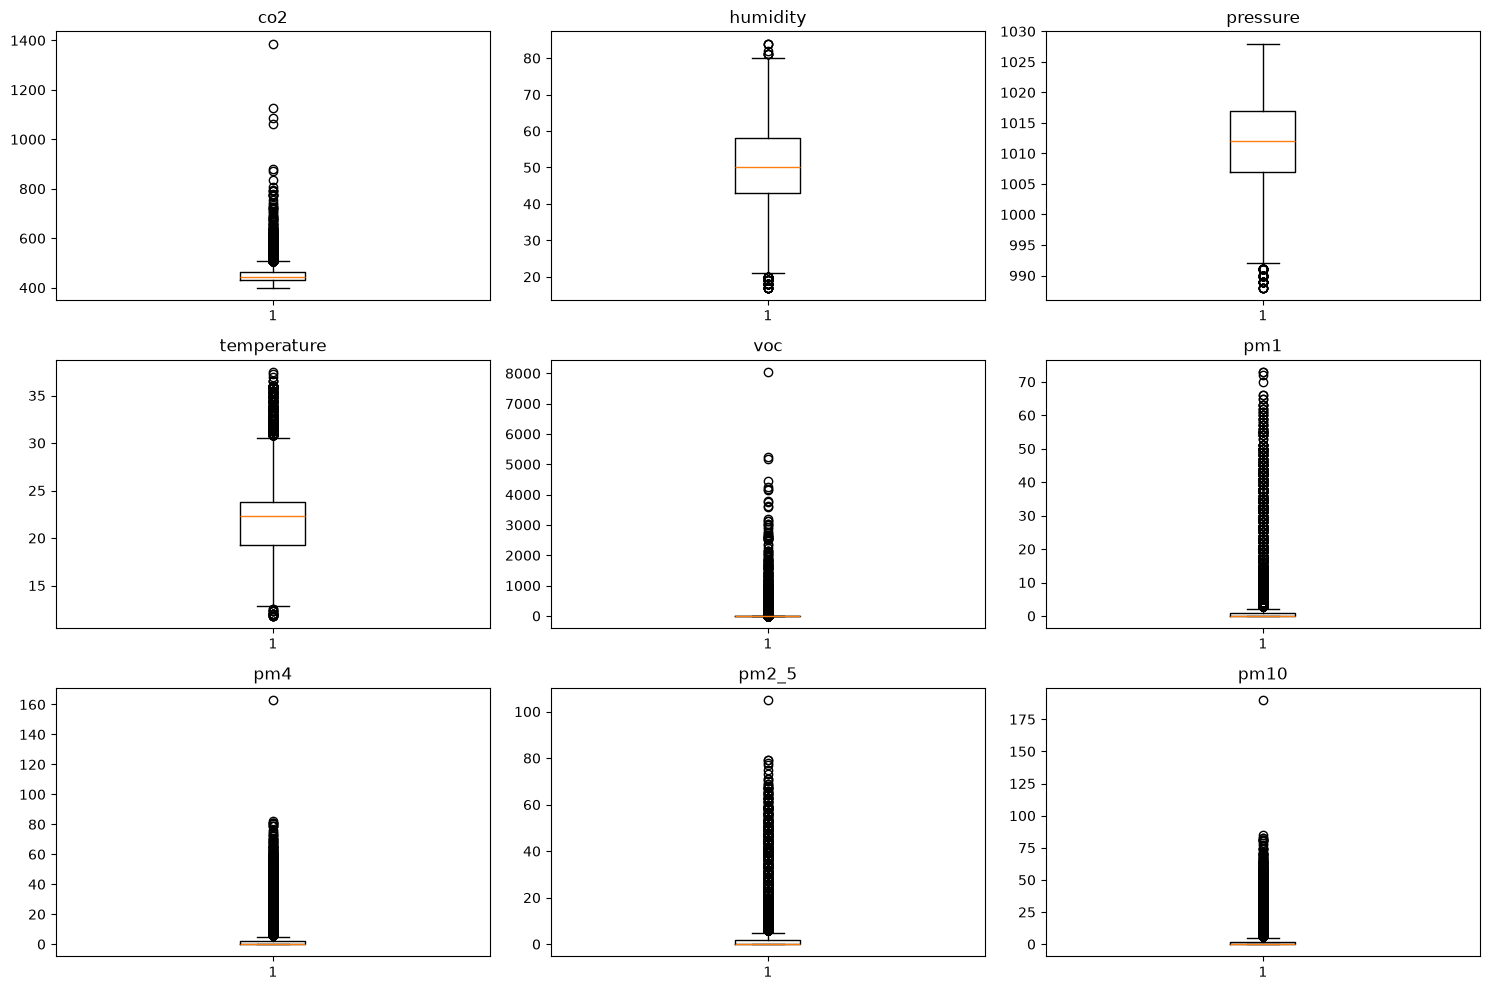

In [66]:
#plotting the datapoints for the room to determine the bounds for the each input/output

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()
cols = ['co2', 'humidity', 'pressure', 'temperature', 'voc', 'pm1', 'pm4', 'pm2_5', 'pm10']

for i, col in enumerate(cols):
    axes[i].boxplot(df_model[col].dropna())
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

In [67]:
#finding the room readings for the unusual temperature readings

sub = df_model[df_model['sensorid'] == 6012002000326].sort_values('timestamp')  # Unknown Room
hot_readings = sub[sub['temperature'] > 32].sort_values('temperature', ascending=False)
print(hot_readings[['timestamp', 'temperature', 'humidity', 'pressure', 'co2']].head(20))

                             timestamp  temperature  humidity  pressure  co2
29619 2026-01-09 05:36:04.583513+00:00         37.5        18       992  418
29620 2026-01-09 06:07:56.224677+00:00         37.3        18       992  413
29618 2026-01-09 05:14:46.644722+00:00         37.0        19       993  423
29616 2026-01-09 04:21:40.477567+00:00         36.5        20       993  420
29621 2026-01-09 06:39:48.991112+00:00         36.5        26       994  411
29617 2026-01-09 04:32:17.676535+00:00         36.5        20       993  420
29359 2026-01-07 06:04:41.069080+00:00         36.0        20      1004  426
29361 2026-01-07 06:25:59.078083+00:00         36.0        19      1004  417
29362 2026-01-07 06:36:36.562609+00:00         36.0        18      1004  427
29365 2026-01-07 07:08:28.520726+00:00         36.0        18      1004  413
29366 2026-01-07 07:19:05.911130+00:00         36.0        18      1004  423
29364 2026-01-07 06:57:51.234623+00:00         36.0        18      1004  427

In [68]:
# Top VOC readings — see what else was happening at those moments
sub = df_model.sort_values('timestamp')  # full combined dataset, or filter by sensorid if you want per-sensor
top_voc = sub.sort_values('voc', ascending=False).head(20)
print(top_voc[['timestamp', 'sensorid', 'voc', 'co2', 'temperature', 'humidity', 'pm1', 'pm2_5']])

                             timestamp       sensorid     voc  co2  \
42009 2026-04-16 09:25:30.913293+00:00  6012002000326  8051.0  486   
39177 2026-03-26 10:45:17.857454+00:00  6012002000326  5246.0  471   
42158 2026-04-17 11:49:28.730583+00:00  6012002000326  5168.0  495   
42557 2026-04-20 10:40:42.069894+00:00  6012002000326  4436.0  498   
40121 2026-04-02 10:18:30.836611+00:00  6012002000326  4267.0  453   
35919 2026-03-02 08:49:03.240673+00:00  6012002000326  4183.0  470   
42695 2026-04-21 11:18:04.399715+00:00  6012002000326  4146.0  494   
41738 2026-04-14 09:11:26.702843+00:00  6012002000326  3798.0  474   
32234 2026-01-29 10:41:32.479835+00:00  6012002000326  3761.0  526   
38762 2026-03-23 09:01:40.640910+00:00  6012002000326  3614.0  490   
30562 2026-01-17 02:04:51.876815+00:00  6012002000326  3608.0  484   
37004 2026-03-10 09:28:18.400911+00:00  6012002000326  3210.0  442   
30874 2026-01-19 09:23:42.797928+00:00  6012002000326  3124.0  444   
22900 2025-11-18 10:

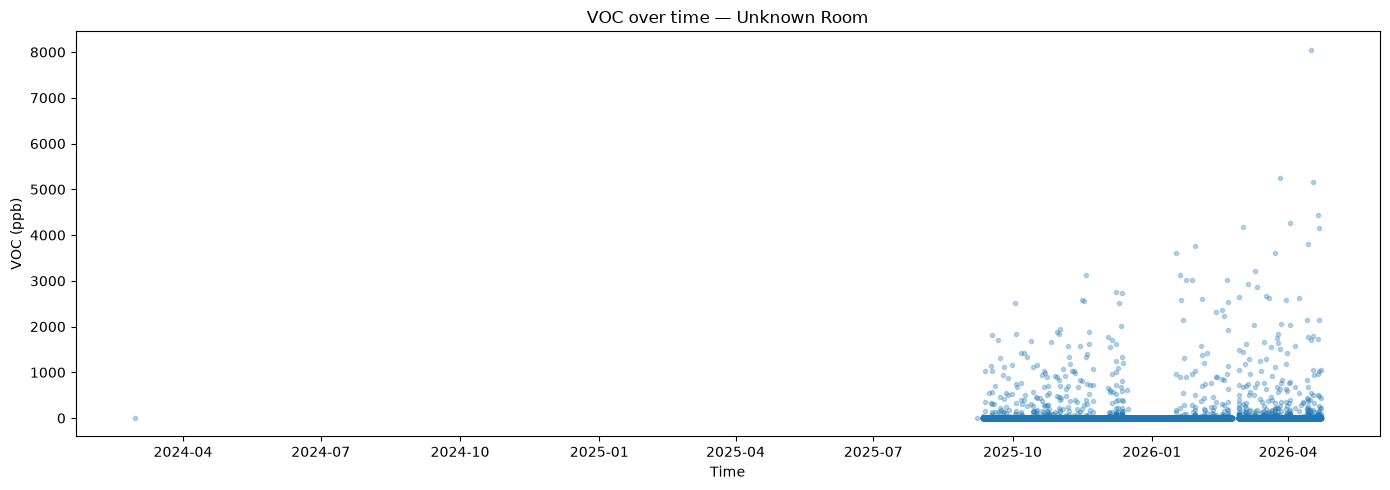

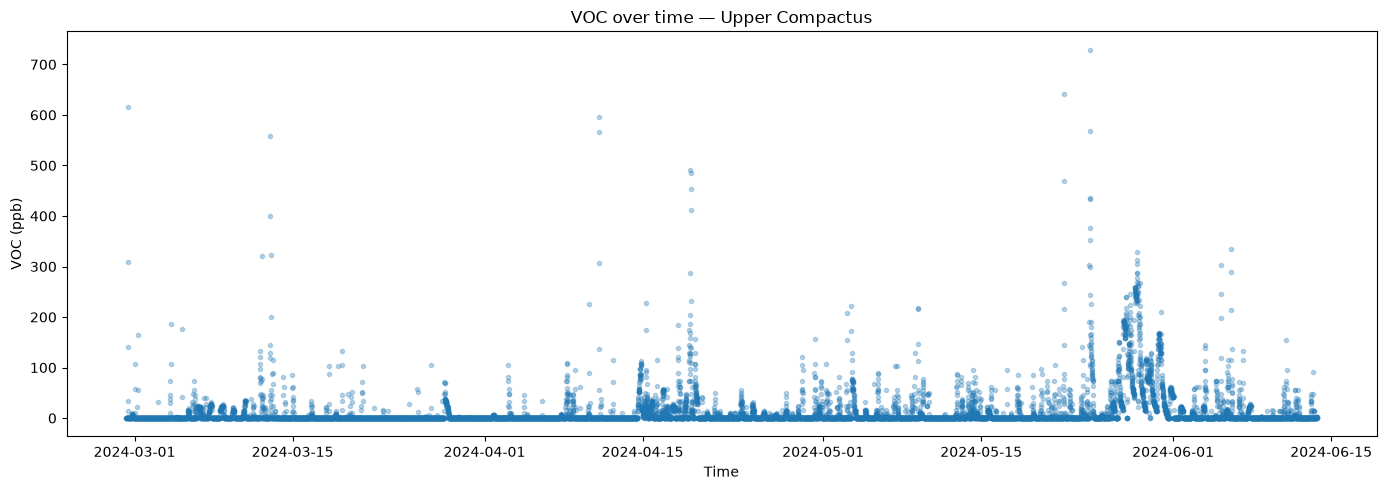

In [69]:
# VOC over time, per sensor, to see if it's isolated spikes or clustered events
for sid in df_model['sensorid'].unique():
    sensor_label = sensor_names.get(sid, str(sid))
    sensor_sub = df_model[df_model['sensorid'] == sid].sort_values('timestamp')
    
    plt.figure(figsize=(14, 5))
    plt.plot(sensor_sub['timestamp'], sensor_sub['voc'], marker='.', linestyle='none', alpha=0.3)
    plt.xlabel('Time')
    plt.ylabel('VOC (ppb)')
    plt.title(f'VOC over time — {sensor_label}')
    plt.tight_layout()
    plt.show()

In [70]:
sub_voc_spikes = df_model[(df_model['sensorid'] == 6012002000326) & (df_model['voc'] > 1000)]
sub_voc_spikes_local = sub_voc_spikes['timestamp'].dt.tz_convert('Australia/Melbourne')
print(sub_voc_spikes_local.dt.hour.value_counts().sort_index())

timestamp
0      1
13     1
14     3
15     1
16     2
17     1
18     3
19    17
20    21
21    50
22    17
23     1
Name: count, dtype: int64


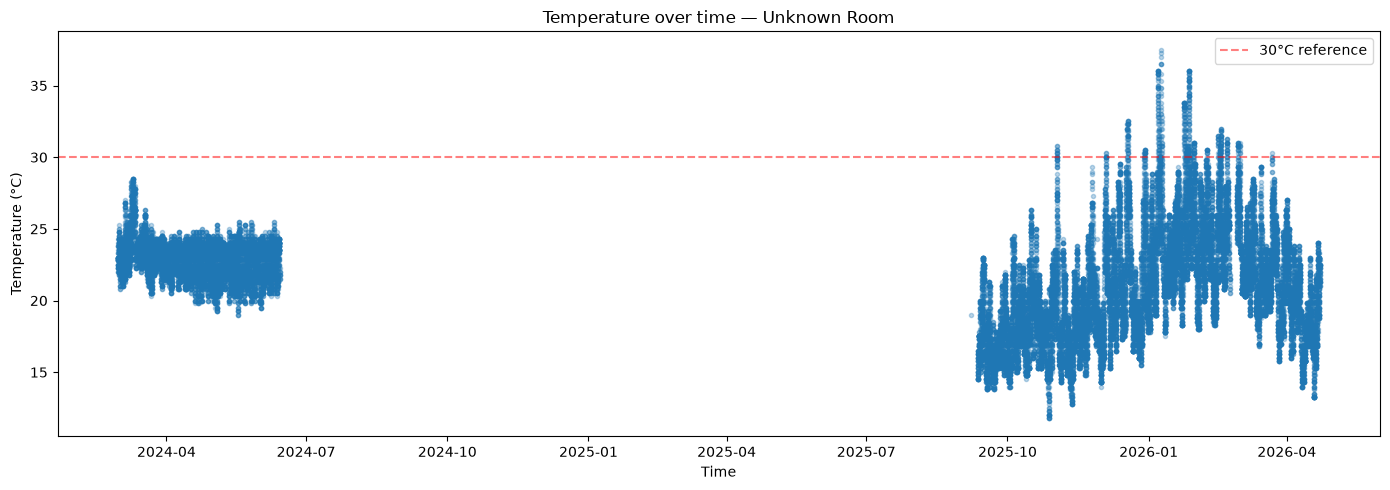

In [71]:
#visualising the unusual temperature readings of the unknown room sensor readings

plt.figure(figsize=(14, 5))
plt.plot(sub['timestamp'], sub['temperature'], marker='.', linestyle='none', alpha=0.3)
plt.axhline(30, color='red', linestyle='--', alpha=0.5, label='30°C reference')
plt.xlabel('Time')
plt.ylabel('Temperature (°C)')
plt.title('Temperature over time — Unknown Room')
plt.legend()
plt.tight_layout()
plt.show()

In [72]:
#generating correlation matrix
import numpy as np

# Select only the numeric sensor columns (exclude IDs/timestamps)
numeric_cols = ['co2', 'humidity', 'pressure', 'temperature', 'voc', 'pm1', 'pm4', 'pm2_5', 'pm10']

corr_matrix = df_model[numeric_cols].corr()

# Just the CO2 row, sorted by strength of correlation (most important view)
co2_corr = corr_matrix['co2'].sort_values(ascending=False)
print(co2_corr)

co2            1.000000
pressure       0.406001
pm10           0.173754
pm4            0.171545
pm2_5          0.154721
pm1            0.127712
temperature    0.062153
voc            0.050396
humidity      -0.058503
Name: co2, dtype: float64


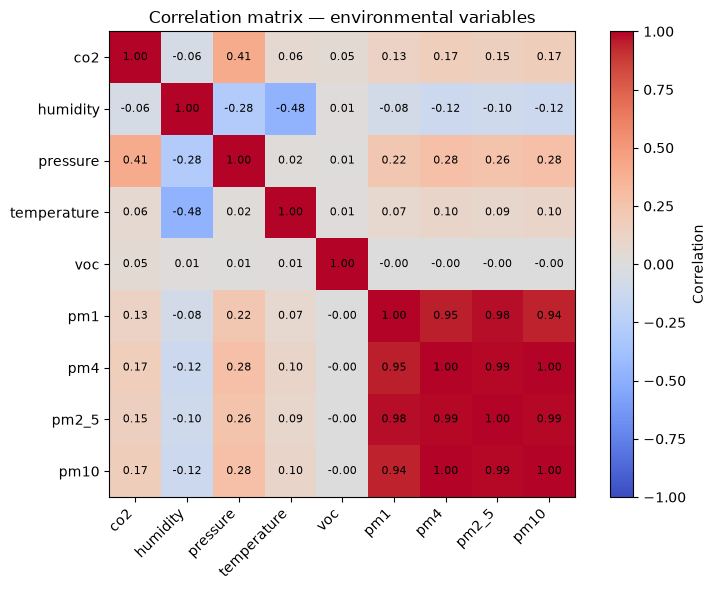

In [73]:
#generating a correlation matrix to understand what could link co2 to the other parameters
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation')
plt.xticks(range(len(numeric_cols)), numeric_cols, rotation=45, ha='right')
plt.yticks(range(len(numeric_cols)), numeric_cols)

# Add the actual correlation values as text on each cell
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        plt.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)

plt.title('Correlation matrix — environmental variables')
plt.tight_layout()
plt.show()

co2        -0.057573
pressure    0.002466
hour        1.000000
Name: hour, dtype: float64


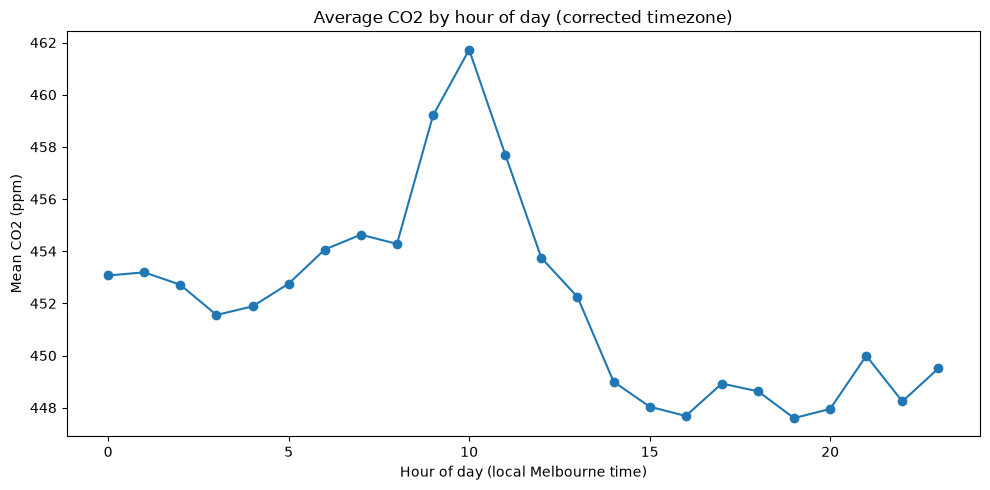

In [74]:
# Does pressure vary mainly with season/time, independent of daily occupancy cycles?
df_model['local_time'] = df_model['timestamp'].dt.tz_convert('Australia/Melbourne')
df_model['hour'] = df_model['local_time'].dt.hour

# Compare CO2's correlation with hour-of-day vs pressure's correlation with hour-of-day
print(df_model[['co2', 'pressure', 'hour']].corr()['hour'])

hourly_pattern = df_model.groupby('hour')['co2'].mean()

plt.figure(figsize=(10, 5))
plt.plot(hourly_pattern.index, hourly_pattern.values, marker='o')
plt.xlabel('Hour of day (local Melbourne time)')
plt.ylabel('Mean CO2 (ppm)')
plt.title('Average CO2 by hour of day (corrected timezone)')
plt.tight_layout()
plt.show()

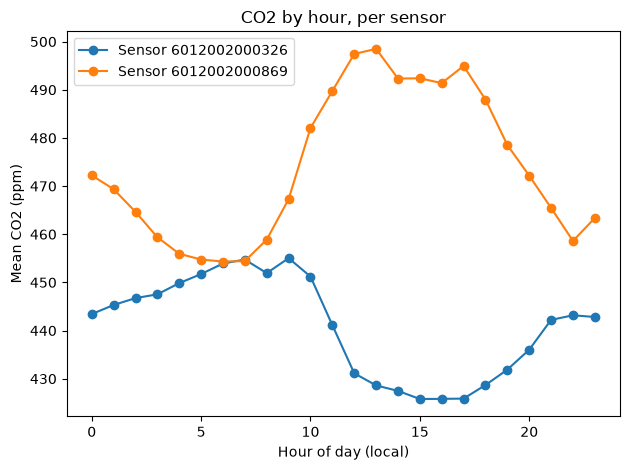

In [75]:
for sid in df_model['sensorid'].unique():
    sensor_hourly = df_model[df_model['sensorid'] == sid].groupby('hour')['co2'].mean()
    plt.plot(sensor_hourly.index, sensor_hourly.values, marker='o', label=f'Sensor {sid}')

plt.xlabel('Hour of day (local)')
plt.ylabel('Mean CO2 (ppm)')
plt.legend()
plt.title('CO2 by hour, per sensor')
plt.tight_layout()
plt.show()

In [76]:
for sid in df_model['sensorid'].unique():
    sub = df_model[df_model['sensorid'] == sid]
    print(f"\nSensor {sid}:")
    print(sub[['co2', 'humidity', 'pressure', 'temperature', 'voc', 'pm1', 'pm4', 'pm2_5', 'pm10', 'hour']].corr()['co2'].sort_values(ascending=False))


Sensor 6012002000326:
co2            1.000000
humidity       0.242624
pressure       0.130907
voc            0.085323
pm2_5          0.034721
pm4            0.033923
pm10           0.033725
pm1            0.032892
temperature   -0.160069
hour          -0.218133
Name: co2, dtype: float64

Sensor 6012002000869:
co2            1.000000
pressure       0.304985
temperature    0.170572
hour           0.135035
voc            0.042331
humidity       0.010713
pm1           -0.075531
pm2_5         -0.078499
pm4           -0.079480
pm10          -0.079563
Name: co2, dtype: float64


In [77]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

#full feature set being the same for both sensors
features = ['humidity', 'pressure', 'temperature', 'voc', 'pm1', 'pm4', 'pm2_5', 'pm10', 'hour']

results = {}

# looping through each sensor separately, sorting the data chronologically
for sid in df_model['sensorid'].unique():
    sensor_label = sensor_names.get(sid, str(sid))
    sub = df_model[df_model['sensorid'] == sid].sort_values('timestamp')
    
    # splitting the data with 80% being the training and 20% being validation data (future period), split by time
    split_idx = int(len(sub) * 0.8)
    train, test = sub.iloc[:split_idx], sub.iloc[split_idx:]
    
    X_train, y_train = train[features], train['co2']
    X_test, y_test = test[features], test['co2']
    
    # using initially a linear regression model, evaluating with RMSE, MAE and R^2
    lr = LinearRegression().fit(X_train, y_train)
    lr_pred = lr.predict(X_test)
    lr_rmse = root_mean_squared_error(y_test, lr_pred)
    lr_mae = mean_absolute_error(y_test, lr_pred)
    lr_r2 = r2_score(y_test, lr_pred)
    
    # # using decision tree regression with max depth of 5, same three metrics
    # dt = DecisionTreeRegressor(max_depth=5, random_state=42).fit(X_train, y_train)
    # dt_pred = dt.predict(X_test)
    # dt_rmse = root_mean_squared_error(y_test, dt_pred)
    # dt_mae = mean_absolute_error(y_test, dt_pred)
    # dt_r2 = r2_score(y_test, dt_pred)
    
    results[sid] = {
        'label': sensor_label,
        'linear_rmse': lr_rmse, 'linear_mae': lr_mae, 'linear_r2': lr_r2,
    }
    
    print(f"\n{sensor_label} (Sensor {sid}):")
    print(f"  Linear Regression  — RMSE={lr_rmse:.2f} ppm, MAE={lr_mae:.2f} ppm, R²={lr_r2:.3f}")
    


Unknown Room (Sensor 6012002000326):
  Linear Regression  — RMSE=29.58 ppm, MAE=18.11 ppm, R²=0.035

Upper Compactus (Sensor 6012002000869):
  Linear Regression  — RMSE=34.22 ppm, MAE=27.54 ppm, R²=-1.400


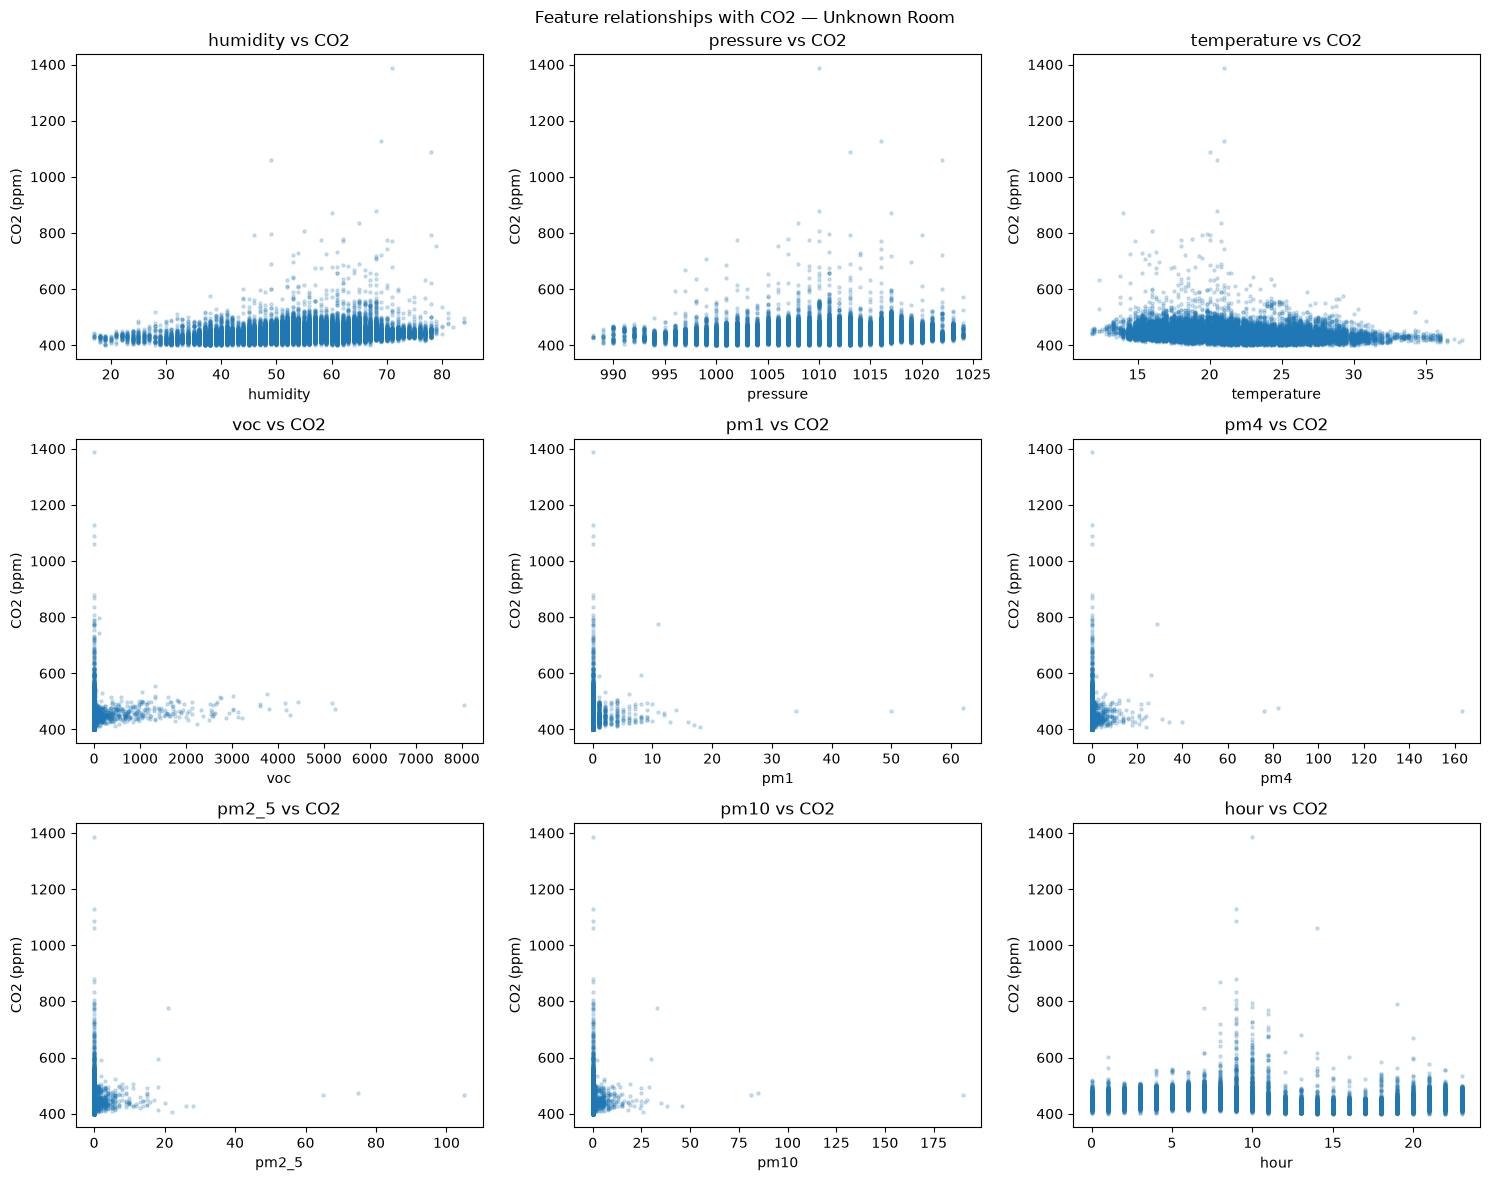

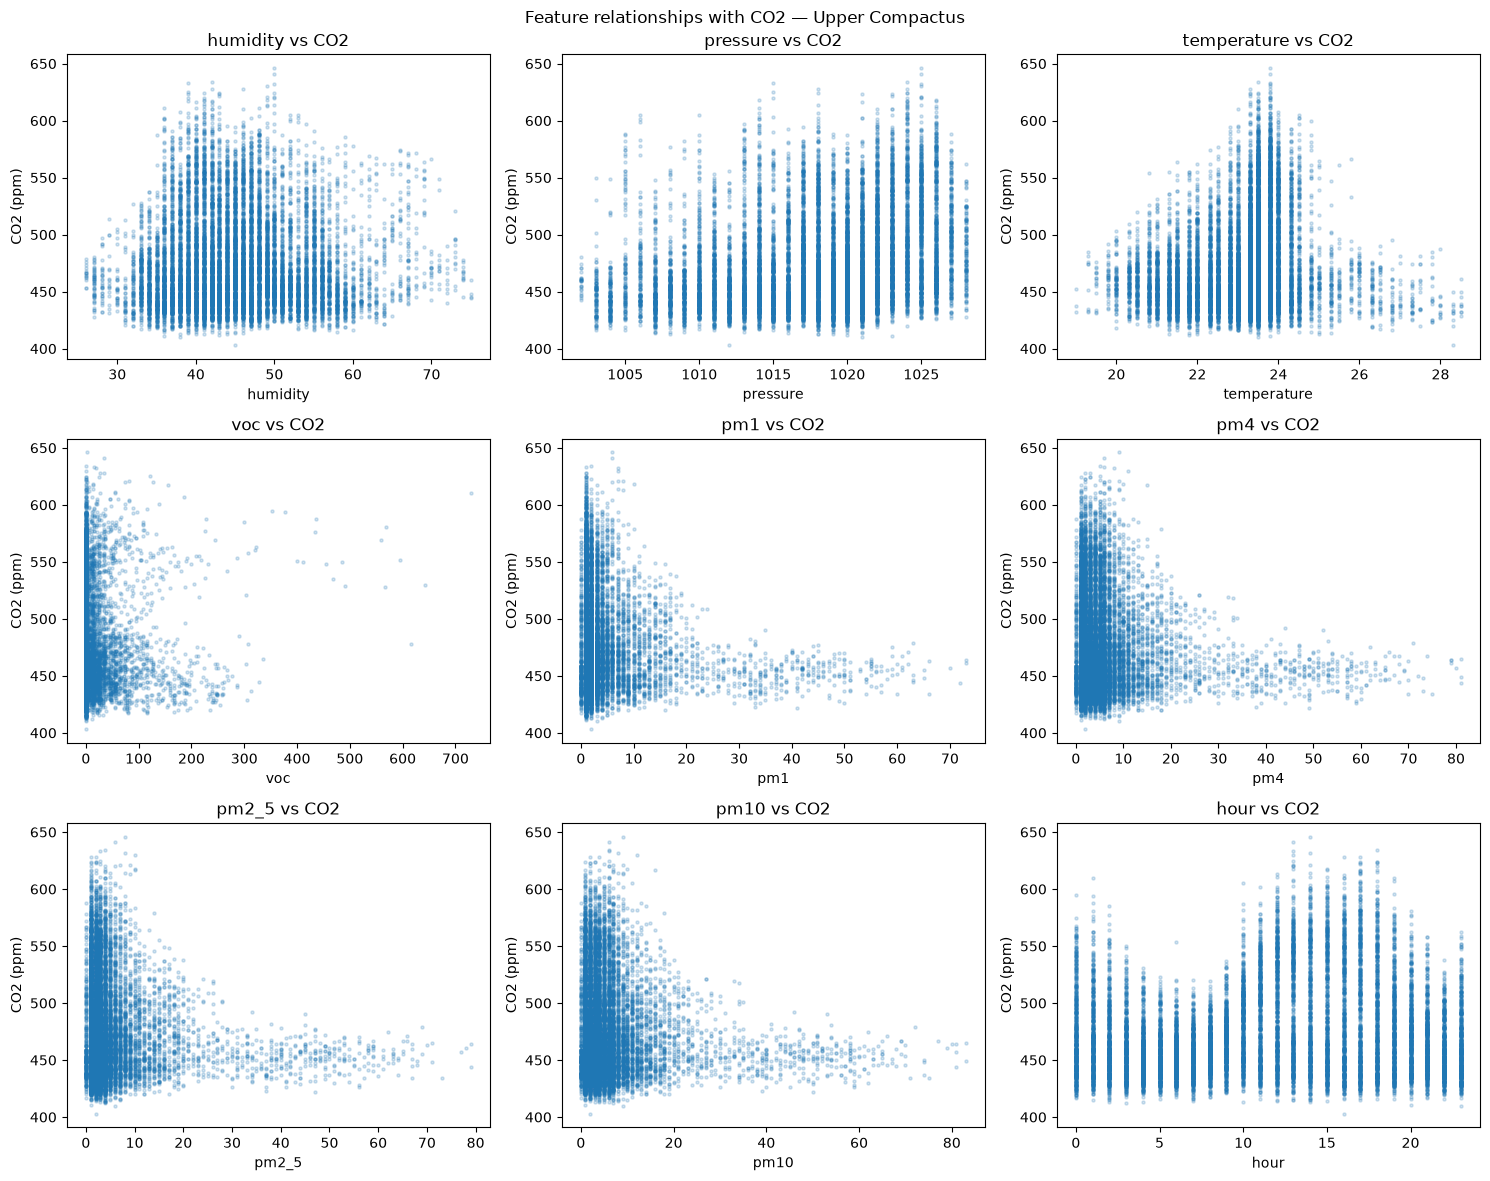

In [78]:
for sid in df_model['sensorid'].unique():
    sensor_label = sensor_names.get(sid, str(sid))
    sub = df_model[df_model['sensorid'] == sid]

    fig, axes = plt.subplots(3, 3, figsize=(15, 12))
    axes = axes.flatten()

    for i, feat in enumerate(features):
        axes[i].scatter(sub[feat], sub['co2'], alpha=0.2, s=5)
        axes[i].set_xlabel(feat)
        axes[i].set_ylabel('CO2 (ppm)')
        axes[i].set_title(f'{feat} vs CO2')

    fig.suptitle(f'Feature relationships with CO2 — {sensor_label}')
    plt.tight_layout()
    plt.show()

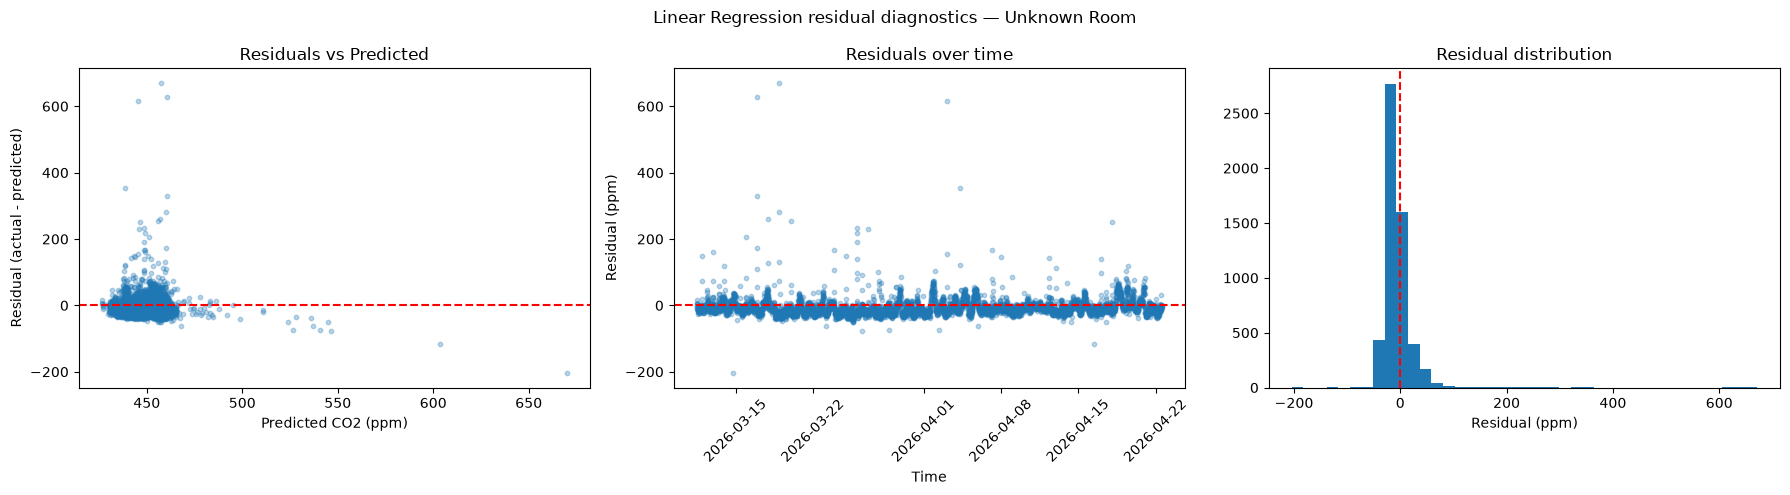

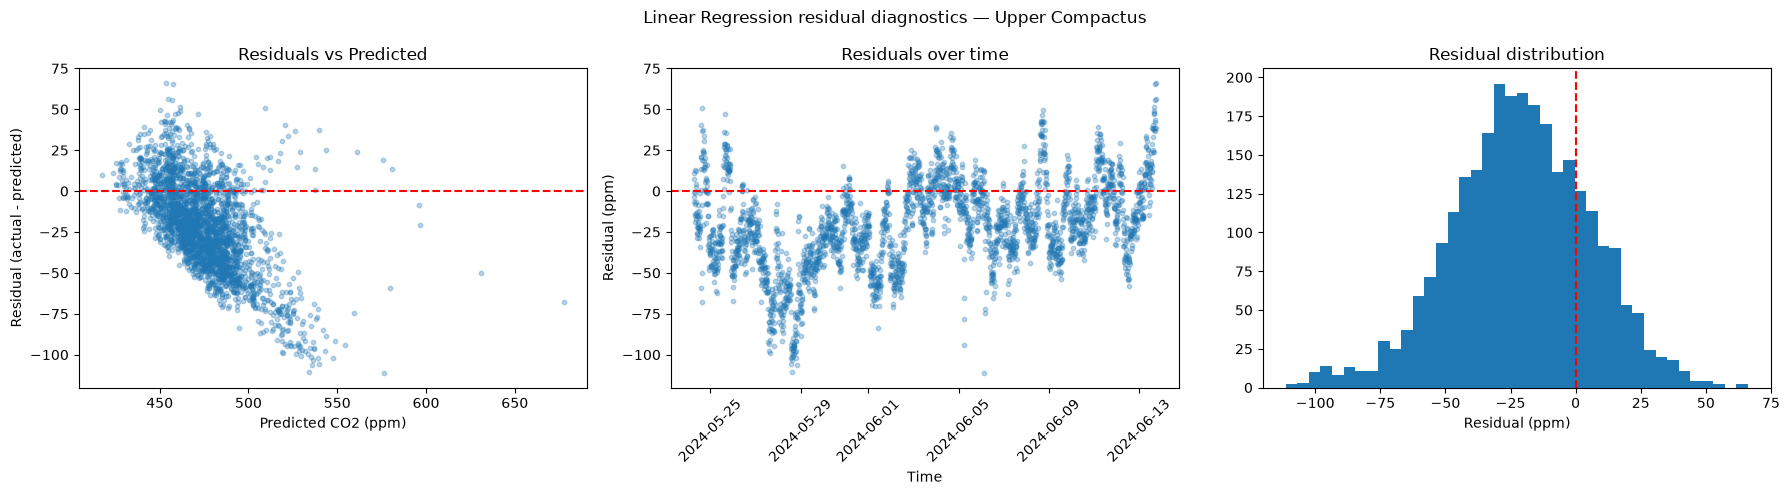

In [79]:
for sid in df_model['sensorid'].unique():
    sensor_label = sensor_names.get(sid, str(sid))
    sub = df_model[df_model['sensorid'] == sid].sort_values('timestamp')
    split_idx = int(len(sub) * 0.8)
    train, test = sub.iloc[:split_idx], sub.iloc[split_idx:]
    X_train, y_train = train[features], train['co2']
    X_test, y_test = test[features], test['co2']

    lr = LinearRegression().fit(X_train, y_train)
    pred = lr.predict(X_test)
    residuals = y_test - pred

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    axes[0].scatter(pred, residuals, alpha=0.3, s=10)
    axes[0].axhline(0, color='red', linestyle='--')
    axes[0].set_xlabel('Predicted CO2 (ppm)')
    axes[0].set_ylabel('Residual (actual - predicted)')
    axes[0].set_title('Residuals vs Predicted')

    axes[1].scatter(test['timestamp'], residuals, alpha=0.3, s=10)
    axes[1].axhline(0, color='red', linestyle='--')
    axes[1].set_xlabel('Time')
    axes[1].set_ylabel('Residual (ppm)')
    axes[1].set_title('Residuals over time')
    axes[1].tick_params(axis='x', rotation=45)

    axes[2].hist(residuals, bins=40)
    axes[2].axvline(0, color='red', linestyle='--')
    axes[2].set_xlabel('Residual (ppm)')
    axes[2].set_title('Residual distribution')

    fig.suptitle(f'Linear Regression residual diagnostics — {sensor_label}')
    plt.tight_layout()
    plt.show()

Unknown Room: SVR RMSE=28.81 ppm, MAE=15.37 ppm, R²=0.085


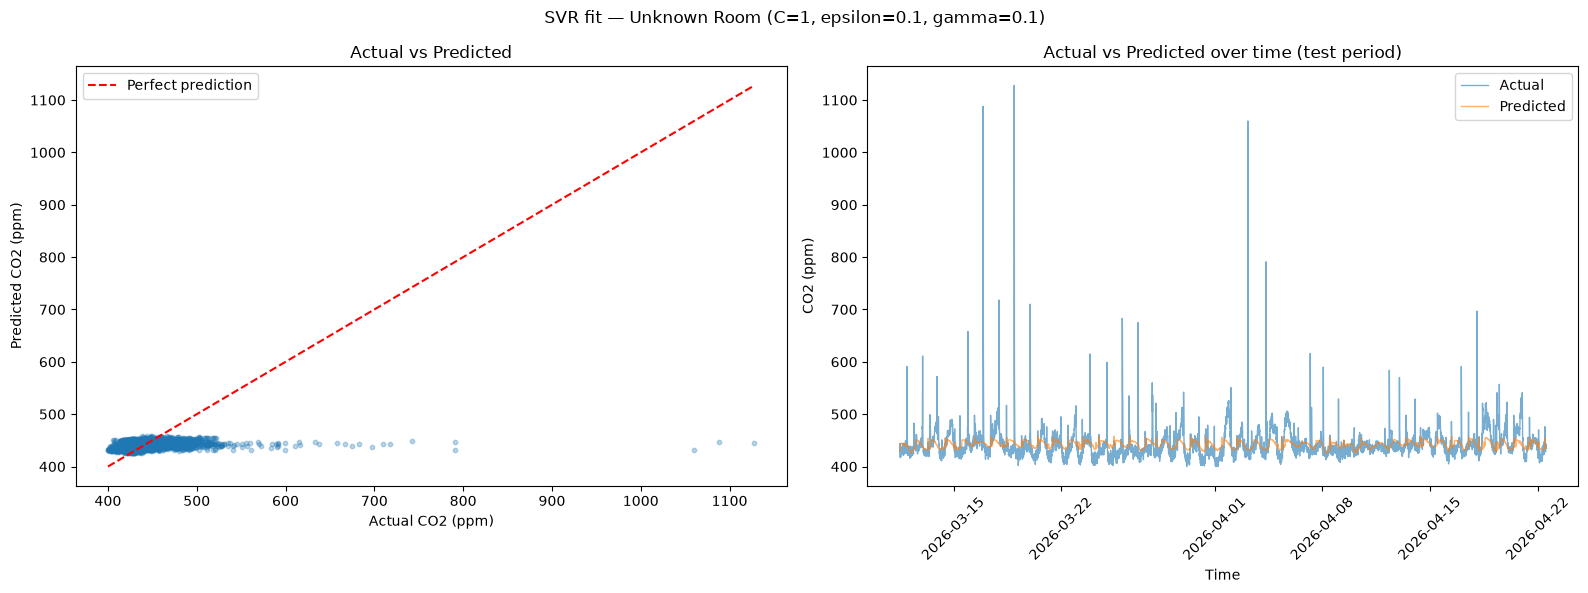

Upper Compactus: SVR RMSE=32.26 ppm, MAE=26.37 ppm, R²=-1.132


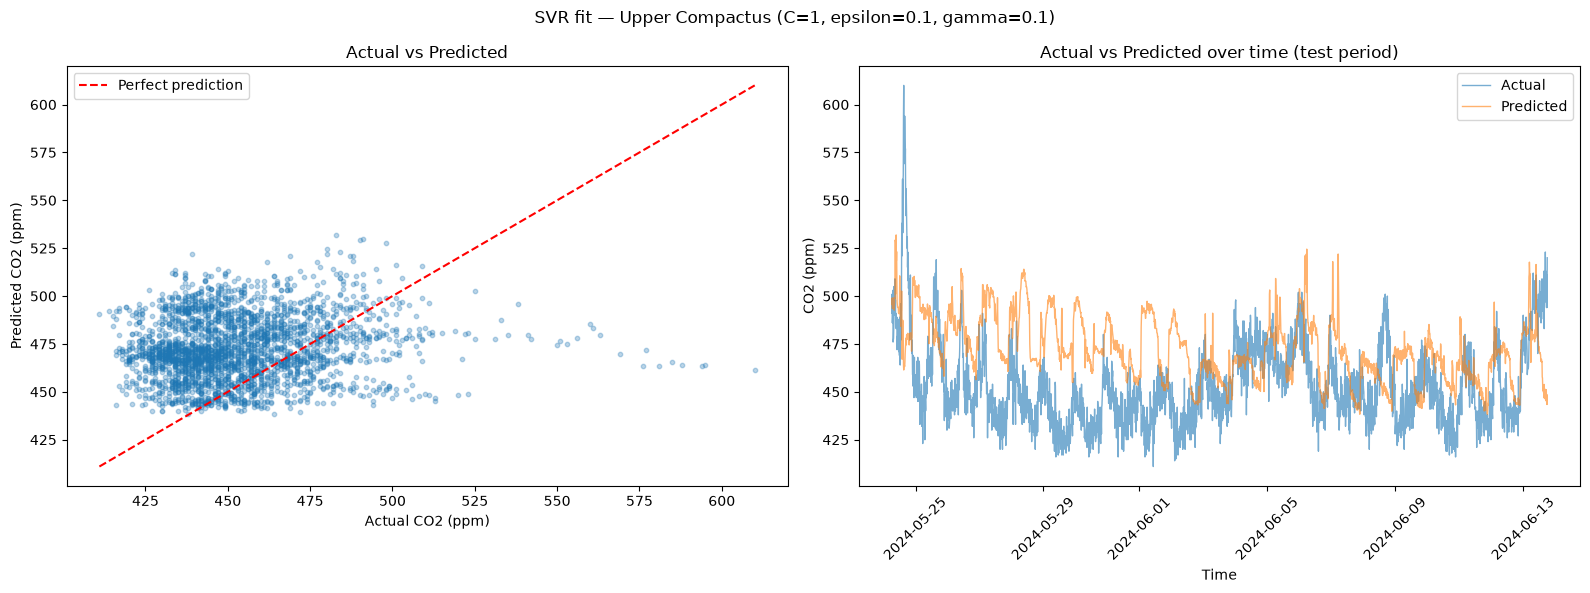

In [80]:
# initial implementation of SVR
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler

svr_models = {}
svr_results = {}

for sid in df_model['sensorid'].unique():
    sensor_label = sensor_names.get(sid, str(sid))
    sub = df_model[df_model['sensorid'] == sid].sort_values('timestamp')
    split_idx = int(len(sub) * 0.8)
    train, test = sub.iloc[:split_idx], sub.iloc[split_idx:]

    X_train, y_train = train[features], train['co2']
    X_test, y_test = test[features], test['co2']

    # Scale features — SVR is distance-based
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Initial SVR model with your chosen starting parameters
    svr = SVR(kernel='rbf', C=1, epsilon=0.1, gamma=0.1).fit(X_train_scaled, y_train)
    pred = svr.predict(X_test_scaled)

    rmse = root_mean_squared_error(y_test, pred)
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)

    svr_models[sid] = {'model': svr, 'scaler': scaler}
    svr_results[sid] = {'rmse': rmse, 'mae': mae, 'r2': r2}

    print(f"{sensor_label}: SVR RMSE={rmse:.2f} ppm, MAE={mae:.2f} ppm, R²={r2:.3f}")

    # --- Visualisation 1: Actual vs Predicted scatter ---
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    axes[0].scatter(y_test, pred, alpha=0.3, s=10)
    lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
    axes[0].plot(lims, lims, color='red', linestyle='--', label='Perfect prediction')
    axes[0].set_xlabel('Actual CO2 (ppm)')
    axes[0].set_ylabel('Predicted CO2 (ppm)')
    axes[0].set_title('Actual vs Predicted')
    axes[0].legend()

    # --- Visualisation 2: Actual vs Predicted over time ---
    axes[1].plot(test['timestamp'], y_test.values, label='Actual', alpha=0.6, linewidth=1)
    axes[1].plot(test['timestamp'], pred, label='Predicted', alpha=0.6, linewidth=1)
    axes[1].set_xlabel('Time')
    axes[1].set_ylabel('CO2 (ppm)')
    axes[1].set_title('Actual vs Predicted over time (test period)')
    axes[1].legend()
    axes[1].tick_params(axis='x', rotation=45)

    fig.suptitle(f'SVR fit — {sensor_label} (C=1, epsilon=0.1, gamma=0.1)')
    plt.tight_layout()
    plt.show()

In [81]:
# Quick pooled check — does combining both sensors hurt performance?
sub_pooled = df_model.sort_values('timestamp')
split_idx = int(len(sub_pooled) * 0.8)
train_pooled, test_pooled = sub_pooled.iloc[:split_idx], sub_pooled.iloc[split_idx:]

X_train_p, y_train_p = train_pooled[features], train_pooled['co2']
X_test_p, y_test_p = test_pooled[features], test_pooled['co2']

lr_pooled = LinearRegression().fit(X_train_p, y_train_p)
pred_pooled = lr_pooled.predict(X_test_p)

print(f"Pooled (both sensors): RMSE={root_mean_squared_error(y_test_p, pred_pooled):.2f} ppm, "
      f"MAE={mean_absolute_error(y_test_p, pred_pooled):.2f} ppm, R²={r2_score(y_test_p, pred_pooled):.3f}")

Pooled (both sensors): RMSE=36.14 ppm, MAE=26.12 ppm, R²=-0.320


Unknown Room: best C=10, best gamma=0.1, RMSE=28.77 ppm


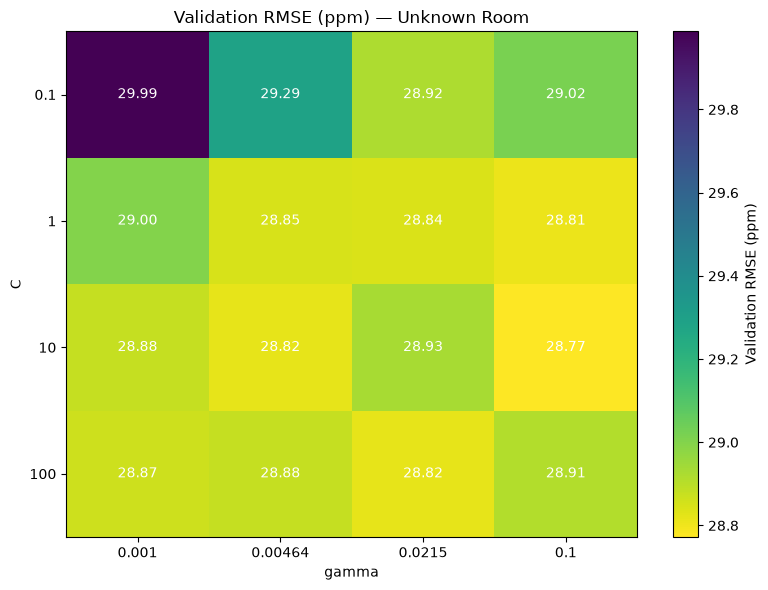

Upper Compactus: best C=0.01, best gamma=10, RMSE=26.48 ppm


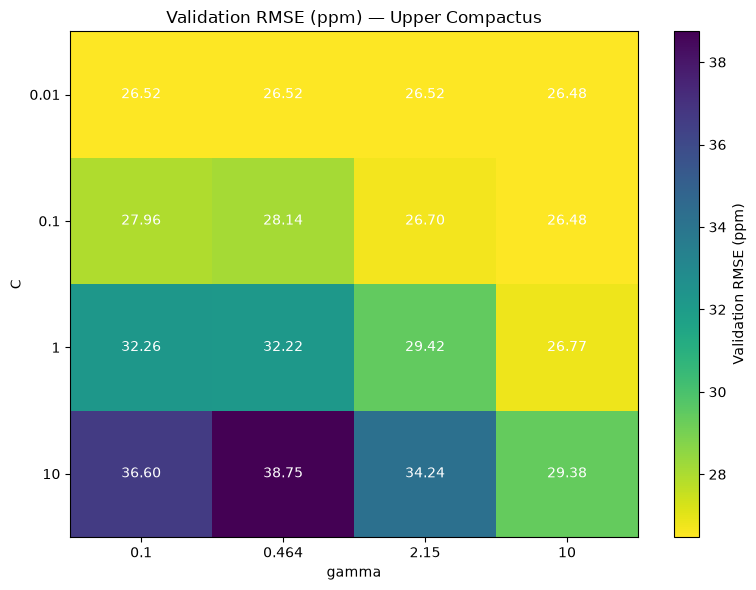

In [82]:
#getting a heatmap of the validation RMSE results for C and gamma parameters on the data for each sensor

# Per-sensor grids
sensor_grids = {
    6012002000326: {  # Unknown Room
        'C_values': np.logspace(-1, 2, 4),      # 0.1, 1, 10, 100
        'gamma_values': np.logspace(-3, -1, 4),  # 0.001, 0.01, 0.1, ~0.46
    },
    6012002000869: {  # Upper Compactus
        'C_values': np.logspace(-2, 1, 4),      # 0.01, 0.1, 1, 10
        'gamma_values': np.logspace(-1, 1, 4),   # 0.1, ~0.46, ~2.15, 10
    },
}

best_params = {}

for sid in df_model['sensorid'].unique():
    sensor_label = sensor_names.get(sid, str(sid))
    C_values = sensor_grids[sid]['C_values']
    gamma_values = sensor_grids[sid]['gamma_values']

    sub = df_model[df_model['sensorid'] == sid].sort_values('timestamp')
    split_idx = int(len(sub) * 0.8)
    train, test = sub.iloc[:split_idx], sub.iloc[split_idx:]

    X_train, y_train = train[features], train['co2']
    X_test, y_test = test[features], test['co2']

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    rmse_grid = np.zeros((len(C_values), len(gamma_values)))

    for i, C in enumerate(C_values):
        for j, gamma in enumerate(gamma_values):
            svr = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=0.1).fit(X_train_scaled, y_train)
            pred = svr.predict(X_test_scaled)
            rmse_grid[i, j] = root_mean_squared_error(y_test, pred)

    best_i, best_j = np.unravel_index(np.argmin(rmse_grid), rmse_grid.shape)
    best_C, best_gamma = C_values[best_i], gamma_values[best_j]
    best_rmse = rmse_grid[best_i, best_j]
    best_params[sid] = {'C': best_C, 'gamma': best_gamma, 'rmse': best_rmse}

    print(f"{sensor_label}: best C={best_C:.4g}, best gamma={best_gamma:.4g}, RMSE={best_rmse:.2f} ppm")

    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(rmse_grid, cmap='viridis_r', aspect='auto')

    ax.set_xticks(range(len(gamma_values)))
    ax.set_xticklabels([f'{g:.3g}' for g in gamma_values])
    ax.set_yticks(range(len(C_values)))
    ax.set_yticklabels([f'{c:.3g}' for c in C_values])
    ax.set_xlabel('gamma')
    ax.set_ylabel('C')
    ax.set_title(f'Validation RMSE (ppm) — {sensor_label}')

    for i in range(len(C_values)):
        for j in range(len(gamma_values)):
            ax.text(j, i, f'{rmse_grid[i, j]:.2f}', ha='center', va='center', color='white', fontsize=10)

    fig.colorbar(im, ax=ax, label='Validation RMSE (ppm)')
    plt.tight_layout()
    plt.show()

In [83]:
epsilon_values = [0.01, 0.05, 0.1, 0.5, 1, 2, 5]

for sid in df_model['sensorid'].unique():
    sensor_label = sensor_names.get(sid, str(sid))
    C, gamma = best_params[sid]['C'], best_params[sid]['gamma']
    
    sub = df_model[df_model['sensorid'] == sid].sort_values('timestamp')
    split_idx = int(len(sub) * 0.8)
    train, test = sub.iloc[:split_idx], sub.iloc[split_idx:]
    X_train, y_train = train[features], train['co2']
    X_test, y_test = test[features], test['co2']
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    print(f"\n{sensor_label} (C={C:.4g}, gamma={gamma:.4g}):")
    for eps in epsilon_values:
        svr = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=eps).fit(X_train_scaled, y_train)
        pred = svr.predict(X_test_scaled)
        rmse = root_mean_squared_error(y_test, pred)
        print(f"  epsilon={eps}: RMSE={rmse:.2f} ppm")


Unknown Room (C=10, gamma=0.1):
  epsilon=0.01: RMSE=28.78 ppm
  epsilon=0.05: RMSE=28.78 ppm
  epsilon=0.1: RMSE=28.77 ppm
  epsilon=0.5: RMSE=28.75 ppm
  epsilon=1: RMSE=28.73 ppm
  epsilon=2: RMSE=28.70 ppm
  epsilon=5: RMSE=28.64 ppm

Upper Compactus (C=0.01, gamma=10):
  epsilon=0.01: RMSE=26.53 ppm
  epsilon=0.05: RMSE=26.51 ppm
  epsilon=0.1: RMSE=26.48 ppm
  epsilon=0.5: RMSE=26.27 ppm
  epsilon=1: RMSE=26.53 ppm
  epsilon=2: RMSE=26.53 ppm
  epsilon=5: RMSE=26.54 ppm


Upper Compactus: best C=0.0001, best gamma=100, RMSE=26.26 ppm


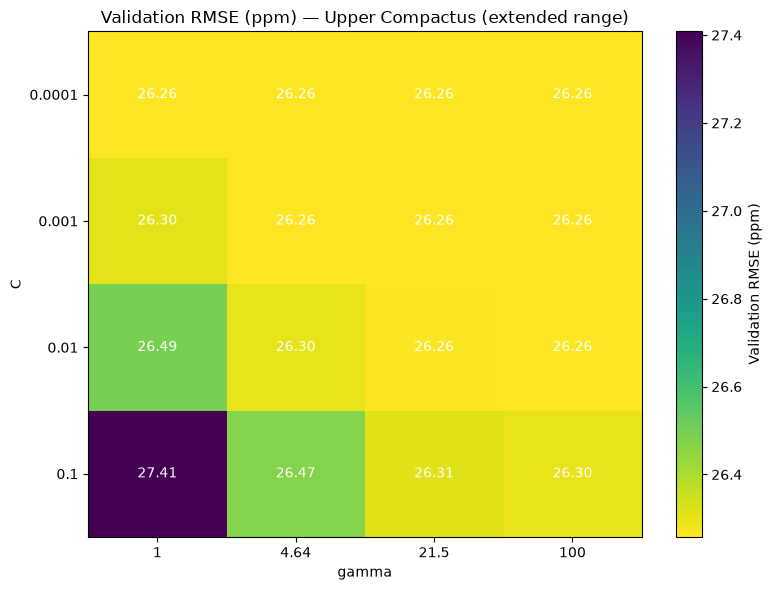

In [84]:
# Upper Compactus: push C lower, gamma higher, following the trend from the last grid
C_values_compactus = np.logspace(-4, -1, 4)    # 0.0001, 0.001, 0.01, 0.1
gamma_values_compactus = np.logspace(0, 2, 4)   # 1, ~4.6, ~21.5, 100

sid = 6012002000869
sensor_label = sensor_names.get(sid, str(sid))

sub = df_model[df_model['sensorid'] == sid].sort_values('timestamp')
split_idx = int(len(sub) * 0.8)
train, test = sub.iloc[:split_idx], sub.iloc[split_idx:]
X_train, y_train = train[features], train['co2']
X_test, y_test = test[features], test['co2']

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

rmse_grid = np.zeros((len(C_values_compactus), len(gamma_values_compactus)))

for i, C in enumerate(C_values_compactus):
    for j, gamma in enumerate(gamma_values_compactus):
        svr = SVR(kernel='rbf', C=C, gamma=gamma, epsilon=0.5).fit(X_train_scaled, y_train)
        pred = svr.predict(X_test_scaled)
        rmse_grid[i, j] = root_mean_squared_error(y_test, pred)

best_i, best_j = np.unravel_index(np.argmin(rmse_grid), rmse_grid.shape)
best_C, best_gamma = C_values_compactus[best_i], gamma_values_compactus[best_j]
best_rmse = rmse_grid[best_i, best_j]

print(f"{sensor_label}: best C={best_C:.4g}, best gamma={best_gamma:.4g}, RMSE={best_rmse:.2f} ppm")

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(rmse_grid, cmap='viridis_r', aspect='auto')
ax.set_xticks(range(len(gamma_values_compactus)))
ax.set_xticklabels([f'{g:.3g}' for g in gamma_values_compactus])
ax.set_yticks(range(len(C_values_compactus)))
ax.set_yticklabels([f'{c:.3g}' for c in C_values_compactus])
ax.set_xlabel('gamma')
ax.set_ylabel('C')
ax.set_title(f'Validation RMSE (ppm) — {sensor_label} (extended range)')
for i in range(len(C_values_compactus)):
    for j in range(len(gamma_values_compactus)):
        ax.text(j, i, f'{rmse_grid[i, j]:.2f}', ha='center', va='center', color='white', fontsize=10)
fig.colorbar(im, ax=ax, label='Validation RMSE (ppm)')
plt.tight_layout()
plt.show()